<a href="https://colab.research.google.com/github/hendipriyadii/RUMAH_KU/blob/main/Natural_gas_consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SYSTEM ANALISA DAN PREDIKSI KONSUMPSI NATURAL GAS PADA ANNEALING FURNACE PT.JSGI)**

### **A. Objektif**


Prediksi konsumsi natural gas adalah salah satu cara untuk menjaga profit perusahaan terhadap pemborosan utility comsuption natural gas. Prediksi konsumsi natural gas menggunakan data riwayat konsumsi natural gas pada setiap sepc produk dan algoritma untuk membangun sistem cerdas yang dapat menentukan nilai target senagai basis control management.


### **B. Menentukan Tujuan Teknis DS**

Prediksi konsumsi natural gas melibatkan analisis berbagai faktor, seperti spesifikasi produk ( Designation, Thickness, Width, Weight, Length ), Parameter produksi ( Annealing code, Line speed ) dan atribut relevan lainnya. Dengan memanfaatkan data historis dan menerapkan algoritme pembelajaran mesin, system dapat membuat model untuk menentukan nilai target untuk bulan selanjutnya.


### **C. Penyiapan dataset**

### Penjelasan data yang akan digunakan

Data yang akan digunakan adalah data record parameter produksi dan spesifikasi produk yang telah diproses secara aktual, data set yang digunakan adalah data selama 9 bulan, 2026-01-01 sampai 2026-09-30.
Target kolom yang akan diprediksi oleh system AI adalah kolom [ANLNG_FURNC_NATUAL_GAS_QT] = Jumlah natual gas yang digunakan untuk proses produksi 1 coil, dengan system ini diharapkan plan konsumsi natural gas akan dapat diprediksi secara akurat, yang selanjutnya nilai  prediksi akan digunakan sebagai nilai kontrol indikator normal.

### **1. Import pustaka (*library*) Python yang diperlukan**

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

### **2. Menyiapkan dataset, source data dari MES_DB**
Gunakan file berikut untuk gather data dari MES_DB :
"C:\Users\vb217249\OneDrive - PT.JFE Steel Galvanizing Indonesia\Training AI Engineer\PROJECT_AI\MES_Gather_data.py"

In [7]:
import pandas as pd

df = pd.read_csv("cgl_analysis_data.csv")

### 2.1 Menyiapkan data

In [8]:
# Menampilkan data fitur
print(df)

      UPDAT_DT INLET_COIL_NO NO1_JSG_DESI_NM NO1_TRG_GRADE_CD  INLET_COIL_TH  \
0      03:25.4        KL7807         CC270DD              CCZ          0.696   
1      08:35.0       KL78071         CC270DD              CCZ          0.696   
2      11:08.8       KH72681         CA440WB              CCZ          0.984   
3      23:15.4       KD69341          CA270D              CCZ          0.977   
4      44:04.1       KD70362          CA270D              CCZ          0.980   
...        ...           ...             ...              ...            ...   
15761  58:56.9        CS7206          CC590R              BBY          0.911   
15762  14:39.6        CV6882          CC590R              BBY          1.010   
15763  33:11.9        CV6782          CC590R              BBY          1.010   
15764  49:59.6        CT5038          CC590R              BBY          1.190   
15765  17:04.2        CT5004          CC590R              BBY          1.190   

       INLET_COIL_WH  INLET_COIL_WT  IN

### 2.2 Menelaah data

In [9]:
# Menampilkan nama kolom fitur
print(df.columns)

Index(['UPDAT_DT', 'INLET_COIL_NO', 'NO1_JSG_DESI_NM', 'NO1_TRG_GRADE_CD',
       'INLET_COIL_TH', 'INLET_COIL_WH', 'INLET_COIL_WT', 'INLET_COIL_LG',
       'LOGIC_LINE_CD', 'NO1_ANLNG_CD', 'AVE_CE_SP', 'DUMMY_SG', 'WORK_DT',
       'ANLNG_FURNC_NATUAL_GAS_QT'],
      dtype='object')


In [10]:
# Menampilkan data 5 baris teratas

print(df.head())

  UPDAT_DT INLET_COIL_NO NO1_JSG_DESI_NM NO1_TRG_GRADE_CD  INLET_COIL_TH  \
0  03:25.4        KL7807         CC270DD              CCZ          0.696   
1  08:35.0       KL78071         CC270DD              CCZ          0.696   
2  11:08.8       KH72681         CA440WB              CCZ          0.984   
3  23:15.4       KD69341          CA270D              CCZ          0.977   
4  44:04.1       KD70362          CA270D              CCZ          0.980   

   INLET_COIL_WH  INLET_COIL_WT  INLET_COIL_LG LOGIC_LINE_CD  NO1_ANLNG_CD  \
0          957.0          16900           3232            A1           750   
1          957.0          13960           2223            A1           750   
2         1151.7           8920           1014            A1           760   
3         1267.4           7940            825            A1           780   
4         1275.0          12490           1284            A1           780   

   AVE_CE_SP DUMMY_SG   WORK_DT  ANLNG_FURNC_NATUAL_GAS_QT  
0       22.0 

In [11]:
# Informasi umum tentang dataset

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15766 entries, 0 to 15765
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   UPDAT_DT                   15766 non-null  object 
 1   INLET_COIL_NO              15766 non-null  object 
 2   NO1_JSG_DESI_NM            15766 non-null  object 
 3   NO1_TRG_GRADE_CD           15766 non-null  object 
 4   INLET_COIL_TH              15766 non-null  float64
 5   INLET_COIL_WH              15766 non-null  float64
 6   INLET_COIL_WT              15766 non-null  int64  
 7   INLET_COIL_LG              15766 non-null  int64  
 8   LOGIC_LINE_CD              15766 non-null  object 
 9   NO1_ANLNG_CD               15766 non-null  int64  
 10  AVE_CE_SP                  15750 non-null  float64
 11  DUMMY_SG                   858 non-null    object 
 12  WORK_DT                    15766 non-null  int64  
 13  ANLNG_FURNC_NATUAL_GAS_QT  15750 non-null  flo

In [12]:
#Hapus kolom tidak terpakai
df = df.drop(columns=['DUMMY_SG', 'UPDAT_DT' , 'INLET_COIL_NO', 'WORK_DT'])

In [13]:
#Data terbaru setelah hapus kolom Dummy
print (df.head)

<bound method NDFrame.head of       NO1_JSG_DESI_NM NO1_TRG_GRADE_CD  INLET_COIL_TH  INLET_COIL_WH  \
0             CC270DD              CCZ          0.696          957.0   
1             CC270DD              CCZ          0.696          957.0   
2             CA440WB              CCZ          0.984         1151.7   
3              CA270D              CCZ          0.977         1267.4   
4              CA270D              CCZ          0.980         1275.0   
...               ...              ...            ...            ...   
15761          CC590R              BBY          0.911         1240.0   
15762          CC590R              BBY          1.010         1074.0   
15763          CC590R              BBY          1.010         1040.0   
15764          CC590R              BBY          1.190          975.0   
15765          CC590R              BBY          1.190          975.0   

       INLET_COIL_WT  INLET_COIL_LG LOGIC_LINE_CD  NO1_ANLNG_CD  AVE_CE_SP  \
0              16900       

In [14]:
#Periksa row yang kososng
df.isnull()

,NO1_JSG_DESI_NM,NO1_TRG_GRADE_CD,INLET_COIL_TH,INLET_COIL_WH,INLET_COIL_WT,INLET_COIL_LG,LOGIC_LINE_CD,NO1_ANLNG_CD,AVE_CE_SP,ANLNG_FURNC_NATUAL_GAS_QT
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
15761,False,False,False,False,False,False,False,False,False,False
15762,False,False,False,False,False,False,False,False,False,False
15763,False,False,False,False,False,False,False,False,False,False
15764,False,False,False,False,False,False,False,False,False,False


### 2.3 Membersihkan Data

Mengisi nilai yang hilang jika ada, misalnya dengan menggunakan nilai mean, median atau modus.

Menghapus data yang tidak relevan atau outlier yang ekstrim.

In [15]:
# Menghapus semua baris yang memiliki cell kosong di DataFrame
df = df.dropna()

In [16]:
#Summaries posisi cell kosong
df.isnull().sum()

,0
NO1_JSG_DESI_NM,0
NO1_TRG_GRADE_CD,0
INLET_COIL_TH,0
INLET_COIL_WH,0
INLET_COIL_WT,0
INLET_COIL_LG,0
LOGIC_LINE_CD,0
NO1_ANLNG_CD,0
AVE_CE_SP,0
ANLNG_FURNC_NATUAL_GAS_QT,0


In [17]:
#Hapus data line speed <50mpm (abnormal)
df_cln = df[df['AVE_CE_SP']>49].copy()
print (df_cln)

      NO1_JSG_DESI_NM NO1_TRG_GRADE_CD  INLET_COIL_TH  INLET_COIL_WH  \
8             CC440KD              CCZ          1.222         1395.7   
9            CC440WBD              CCZ          1.221         1412.0   
10            CC270CD              CCZ          1.140         1514.0   
11            CC440KD              CCZ          0.907         1576.6   
12            CC270DF              BBY          0.995         1702.0   
...               ...              ...            ...            ...   
15761          CC590R              BBY          0.911         1240.0   
15762          CC590R              BBY          1.010         1074.0   
15763          CC590R              BBY          1.010         1040.0   
15764          CC590R              BBY          1.190          975.0   
15765          CC590R              BBY          1.190          975.0   

       INLET_COIL_WT  INLET_COIL_LG LOGIC_LINE_CD  NO1_ANLNG_CD  AVE_CE_SP  \
8               9970            750            A1        

In [18]:
#Informasi data secara keseluruhan
print(df.describe())

       INLET_COIL_TH  INLET_COIL_WH  INLET_COIL_WT  INLET_COIL_LG  \
count   15750.000000   15750.000000   15750.000000   15750.000000   
mean        0.999880    1323.382781   18080.432063    2063.294476   
std         0.444772     249.102607    3240.694612     808.922802   
min         0.496000     800.000000    2970.000000     358.000000   
25%         0.643000    1140.000000   17370.000000    1383.000000   
50%         0.812000    1303.000000   18805.000000    2040.000000   
75%         1.218000    1542.000000   20140.000000    2644.000000   
max         2.650000    1827.000000   24790.000000    5246.000000   

       NO1_ANLNG_CD     AVE_CE_SP  ANLNG_FURNC_NATUAL_GAS_QT  
count  15750.000000  15750.000000               15750.000000  
mean     818.141587    117.096190                 351.069714  
std       42.688035     32.253948                 132.805158  
min      730.000000     10.000000                   0.000000  
25%      780.000000     92.000000                 312.000000  


In [19]:
#Cleaning outlier data consumprtion natural gas
col_target = 'ANLNG_FURNC_NATUAL_GAS_QT'
Q1 = df_cln[col_target].quantile(0.25)
Q3 = df_cln[col_target].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_cln = df_cln[(df_cln[col_target] >= lower_bound) &
                (df_cln[col_target] <= upper_bound)
                ]
print(f"jumlah baris setelah outier cleaning : {len(df_cln)}")


jumlah baris setelah outier cleaning : 14709


In [20]:
#Memuat fitur turunan Therma load untuk membantu model menangkap hubungan fisik konsumsi gas

df_cln['Thermal_Load'] = df_cln['INLET_COIL_WH'] * df_cln['INLET_COIL_TH'] * df_cln['AVE_CE_SP']
print (df_cln.head)

<bound method NDFrame.head of       NO1_JSG_DESI_NM NO1_TRG_GRADE_CD  INLET_COIL_TH  INLET_COIL_WH  \
8             CC440KD              CCZ          1.222         1395.7   
9            CC440WBD              CCZ          1.221         1412.0   
12            CC270DF              BBY          0.995         1702.0   
13            CC270EF              BBY          0.695         1622.0   
14            CC270EF              BBY          0.695         1622.0   
...               ...              ...            ...            ...   
15760         CC590RD              CCZ          0.791         1145.8   
15762          CC590R              BBY          1.010         1074.0   
15763          CC590R              BBY          1.010         1040.0   
15764          CC590R              BBY          1.190          975.0   
15765          CC590R              BBY          1.190          975.0   

       INLET_COIL_WT  INLET_COIL_LG LOGIC_LINE_CD  NO1_ANLNG_CD  AVE_CE_SP  \
8               9970       

In [21]:
print (df_cln.columns)

Index(['NO1_JSG_DESI_NM', 'NO1_TRG_GRADE_CD', 'INLET_COIL_TH', 'INLET_COIL_WH',
       'INLET_COIL_WT', 'INLET_COIL_LG', 'LOGIC_LINE_CD', 'NO1_ANLNG_CD',
       'AVE_CE_SP', 'ANLNG_FURNC_NATUAL_GAS_QT', 'Thermal_Load'],
      dtype='object')


In [22]:
#Encoding Designaton & Taget grade

df_encoded = pd.get_dummies(df_cln, columns=['NO1_JSG_DESI_NM', 'NO1_TRG_GRADE_CD', 'LOGIC_LINE_CD'], drop_first=True)
print(f"Total kolom setelah encoding: {df_encoded.shape[1]}")


Total kolom setelah encoding: 103


### **SPLIT DATA UNTUK Trining 80% - Test 20%**

In [23]:
target_column = 'ANLNG_FURNC_NATUAL_GAS_QT'
X = df_encoded.drop(columns=[target_column])
y = df_encoded[target_column]

#Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Ukuran X_train: {X_train.shape}")
print(f"Ukuran X_test: {X_test.shape}")


Ukuran X_train: (11767, 102)
Ukuran X_test: (2942, 102)


### Scaling data menggunakan standard_scaller

In [24]:
scaler = StandardScaler()

#Fit dan transform hanya pada data training lalu transform pada data testing agar data mode tidak bocor
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### **3.Exploratory Data Analysis (EDA)**

In [25]:
# Korelasi Data  melihat secara matrix correlasi setiap kolom
# Sangat penting di Linear Regression
# Bernilai (-) (0) (+)

df_encoded.corr(numeric_only=True)

,INLET_COIL_TH,INLET_COIL_WH,INLET_COIL_WT,INLET_COIL_LG,NO1_ANLNG_CD,AVE_CE_SP,ANLNG_FURNC_NATUAL_GAS_QT,Thermal_Load,NO1_JSG_DESI_NM_AA270D,NO1_JSG_DESI_NM_AA270DB,...,NO1_JSG_DESI_NM_CC590RD,NO1_JSG_DESI_NM_CC780Y2,NO1_JSG_DESI_NM_CC980Y,NO1_JSG_DESI_NM_CC980YX,NO1_TRG_GRADE_CD_BBY,NO1_TRG_GRADE_CD_BBZ,NO1_TRG_GRADE_CD_CBZ,NO1_TRG_GRADE_CD_CCZ,NO1_TRG_GRADE_CD_SBB,LOGIC_LINE_CD_G1
INLET_COIL_TH,1.000000,-0.391727,-0.194909,-0.815652,0.270097,-0.764057,-0.180024,0.421589,-0.016005,-0.017013,...,0.040044,0.020669,0.186107,0.004391,0.326317,0.000467,0.435886,0.016745,-0.026769,-0.111680
INLET_COIL_WH,-0.391727,1.000000,0.413060,0.026010,-0.388334,0.193558,-0.064650,0.359469,0.003259,-0.003082,...,-0.029615,-0.037168,-0.233111,-0.029423,-0.378114,-0.009400,-0.160734,-0.022961,0.074087,0.158381
INLET_COIL_WT,-0.194909,0.413060,1.000000,0.355631,-0.096396,0.259626,0.563305,0.247901,-0.086083,-0.062596,...,-0.114849,0.002781,-0.332510,-0.082971,-0.183117,-0.081175,-0.014126,-0.386143,0.032107,0.174681
INLET_COIL_LG,-0.815652,0.026010,0.355631,1.000000,-0.158259,0.749278,0.399764,-0.551339,-0.024671,-0.010068,...,-0.069491,-0.016957,-0.204258,-0.050212,-0.275239,-0.027502,-0.236243,-0.161050,-0.007296,0.172349
NO1_ANLNG_CD,0.270097,-0.388334,-0.096396,-0.158259,1.000000,-0.216227,0.438524,-0.017933,-0.027841,-0.018910,...,-0.025804,0.038205,0.360557,0.131653,0.302488,-0.023660,-0.205335,-0.129580,-0.022088,-0.173888
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NO1_TRG_GRADE_CD_BBZ,0.000467,-0.009400,-0.081175,-0.027502,-0.023660,-0.032398,-0.036639,-0.037604,-0.000601,-0.000408,...,-0.001119,-0.000817,-0.004413,-0.001611,-0.026837,1.000000,-0.003543,-0.003172,-0.000958,0.000735
NO1_TRG_GRADE_CD_CBZ,0.435886,-0.160734,-0.014126,-0.236243,-0.205335,-0.286547,-0.277513,0.071569,-0.005217,-0.003543,...,-0.009716,-0.007091,-0.038317,-0.013991,-0.233010,-0.003543,1.000000,-0.027544,-0.008317,0.181896
NO1_TRG_GRADE_CD_CCZ,0.016745,-0.022961,-0.386143,-0.161050,-0.129580,-0.197926,-0.172273,-0.170308,0.189397,0.128639,...,0.352761,-0.006348,-0.034306,-0.012526,-0.208619,-0.003172,-0.027544,1.000000,-0.007447,-0.082176
NO1_TRG_GRADE_CD_SBB,-0.026769,0.074087,0.032107,-0.007296,-0.022088,0.024204,-0.020724,0.046076,-0.001410,-0.000958,...,-0.002627,-0.001917,-0.010359,-0.003783,-0.062995,-0.000958,-0.008317,-0.007447,1.000000,0.049176


In [26]:
import seaborn as sns

sns.pairplot(df_encoded)

KeyboardInterrupt: 

Error in callback <function _draw_all_if_interactive at 0x7b1bcdff2520> (for post_execute):


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x7b1bcdfd3920> (for post_execute):


KeyboardInterrupt: 

In [28]:
# Latih model
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Menampilkan tingkat kepentingan (importance) tiap fitur
importances = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
)

print(importances.sort_values(ascending=False))

INLET_COIL_WT              0.225109
INLET_COIL_LG              0.222938
Thermal_Load               0.172857
AVE_CE_SP                  0.164703
INLET_COIL_WH              0.083547
                             ...   
NO1_JSG_DESI_NM_AA440W     0.000051
NO1_JSG_DESI_NM_AA590Y     0.000040
NO1_JSG_DESI_NM_AC440KD    0.000028
NO1_JSG_DESI_NM_AC340PD    0.000000
NO1_JSG_DESI_NM_AC270DT    0.000000
Length: 102, dtype: float64


### **D. Model Training**

In [29]:
from sklearn.linear_model import LinearRegression

In [30]:
regression=LinearRegression()

In [33]:
regression.fit(X_train_scaled,y_train)

LinearRegression()

In [34]:
# Print the coefficients (slope) dan intercept

print(regression.coef_)

[-2.70055476e+01 -1.32453982e+01  3.20720848e+01  3.47348607e+01
  2.83435109e+00 -3.99791020e+01  1.52040924e+01 -4.75756209e-01
 -2.12112263e-01 -1.96138538e-01 -1.37598262e-01  2.05104479e-01
  4.09116514e-01  9.87056200e-01  1.24781285e+00  1.70130984e+00
 -2.09139775e-02  1.34879319e+00  1.98701998e+00 -3.60878999e+00
 -2.02636241e-01  4.14301495e+00  1.23288855e+00 -7.81537632e+00
 -3.53151872e+00  8.21565038e-15  8.28010249e-01  1.04410792e+00
 -2.10442962e-01 -7.82759507e-01  5.91370516e-01 -1.46770647e-01
  7.64412776e-01  1.66533454e-16  6.30077182e-01 -5.28955620e-01
 -3.62060087e-01 -3.46205152e-01  4.41872519e-01  1.01041020e+00
  1.04438152e+01  3.85033281e-01 -2.13450109e+00 -1.39165277e-02
 -6.34714482e+00 -3.45180435e+00 -5.81464005e+00 -3.40526023e-01
 -7.95105442e-01 -8.56802286e-01  9.81777337e-02  1.93229950e-01
 -4.03079616e-02  2.34509369e-01  8.17848252e-01  1.45317561e+00
 -2.34569859e-01 -2.07374821e-01 -6.17675998e-01 -7.46736579e-01
 -1.90612329e+00  1.59283

In [35]:
print(regression.intercept_)

355.345457635761


In [36]:
# Parameter mana dari model yang sudah di-training

regression.get_params()

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

In [41]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

#Prediksi data uji
y_pred = regression.predict(X_test_scaled)

#Evaluation matrix
r2 = r2_score(y_test, y_pred)
rsme = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"Performance model Regresi Linear:")
print(f"- R Score : {r2: .4f}")
print(f"- RSME    : {rsme: .2f}")
print(f"- MAE     : {mae: .2f}")


#Koefisien bobot tiap kolom
coefficients = pd.Series(regression.coef_, index=X.columns).sort_values(ascending=False)
print("\nKoefisien Pengaruh terhadap konsumsi gas:")
print(coefficients.head(10))

Performance model Regresi Linear:
- R Score :  0.7789
- RSME    :  27.68
- MAE     :  20.62

Koefisien Pengaruh terhadap konsumsi gas:
INLET_COIL_LG               34.734861
INLET_COIL_WT               32.072085
NO1_JSG_DESI_NM_CC590R      15.820709
Thermal_Load                15.204092
NO1_JSG_DESI_NM_AC590R      10.443815
NO1_JSG_DESI_NM_AC270DBF     4.143015
NO1_JSG_DESI_NM_CC980Y       2.850063
NO1_ANLNG_CD                 2.834351
NO1_JSG_DESI_NM_CC270DBK     2.766618
NO1_TRG_GRADE_CD_CCZ         2.610852
dtype: float64


### **E. Prediction dengan data testing**

In [56]:
reg_pred=regression.predict(X_test_scaled)

In [58]:
reg_pred

array([326.3273702 , 374.10467239, 402.38825468, ..., 244.71230704,
       378.98283029, 442.01390155])

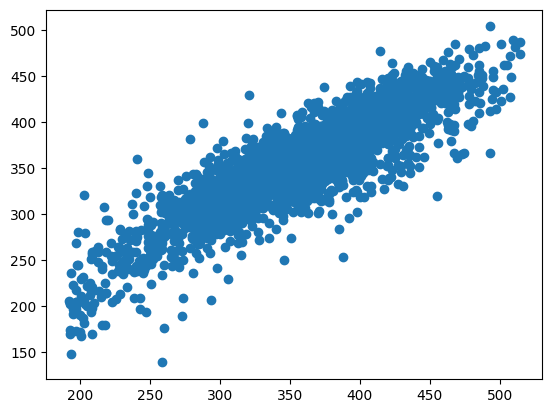

In [59]:
# Scatter plot hasil prediksi

plt.scatter(y_test,reg_pred)

In [65]:
# Residuals

residuals=y_test-reg_pred

In [67]:
residuals

,ANLNG_FURNC_NATUAL_GAS_QT
9450,-12.327370
11855,29.895328
12932,16.611745
8335,-6.698892
2496,20.646365
...,...
12955,23.126378
4564,-5.569266
2447,15.287693
13442,-31.982830


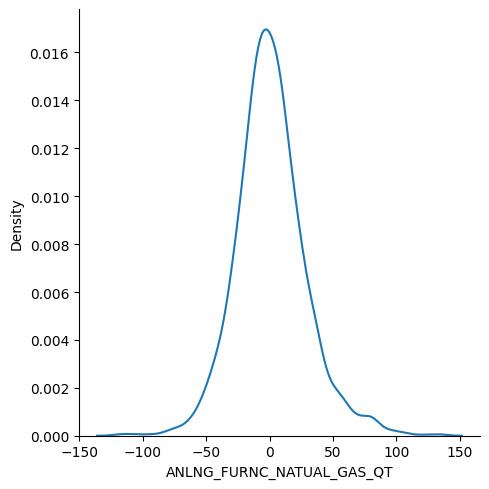

In [62]:
# Plot residuals

# sns.displot(residuals)
sns.displot(residuals,kind="kde")

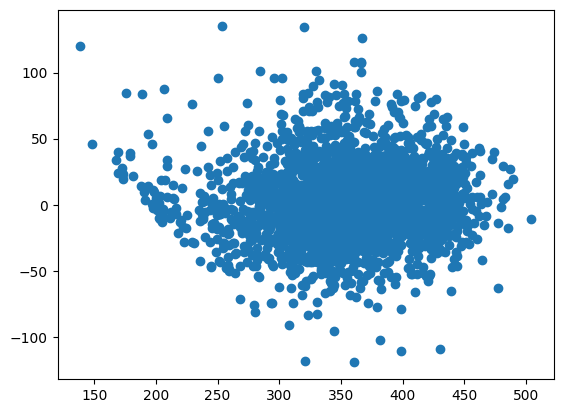

In [63]:
# Scatter plot with respect to prediction dan residuals
# Uniform distribution

plt.scatter(reg_pred,residuals)

In [68]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

print(mean_absolute_error(y_test,reg_pred))
print(mean_squared_error(y_test,reg_pred))
print(np.sqrt(mean_squared_error(y_test,reg_pred)))

20.62431969559228
766.3540363401552
27.68310019380335


### **F. R Square dan Adjusted R Square**

Formula

R^2 = 1 - SSR/SST

R^2 = coefficient of determination SSR = sum of squares of residuals SST = total sum of squares

In [70]:
from sklearn.metrics import r2_score
score=r2_score(y_test,reg_pred)
print(score)

0.7788804772206275


Adjusted R2 = 1 - [(1-R2)*(n-1)/(n-k-1)]

where:

R2: The R2 of the model n: The number of observations k: The number of predictor variables.

In [72]:
# Display adjusted R-squared
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.7709360632285542

### **G. Prediksi Data Baru**

In [93]:
target_column = 'ANLNG_FURNC_NATUAL_GAS_QT'

# Ambil fitur yang sama persis dengan training
data = df_encoded.drop(
    columns=[target_column]
).reindex(
    columns=X_train.columns
).to_numpy(dtype=float)

# Periksa
print(data.shape)
print(data.dtype)

(14709, 102)
float64


In [94]:
data[0]

array([1.2220000e+00, 1.3957000e+03, 9.9700000e+03, 7.5000000e+02,
       7.9000000e+02, 5.5000000e+01, 9.3804997e+04, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e

In [95]:
data[0].shape

(102,)

In [96]:
data[0].reshape(1,-1)

array([[1.2220000e+00, 1.3957000e+03, 9.9700000e+03, 7.5000000e+02,
        7.9000000e+02, 5.5000000e+01, 9.3804997e+04, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e

In [97]:
data[0].reshape(1,-1).shape

(1, 102)

In [99]:
# Transformation of new data (scaling)

scaler.transform(data[0].reshape(1,-1))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[ 5.56664631e-01,  2.68316048e-01, -3.64165969e+00,
        -1.79158522e+00, -7.03859738e-01, -2.13608897e+00,
        -1.42593643e+00, -3.19506212e-02, -2.06178993e-02,
        -1.30382418e-02, -1.59691985e-02, -1.84404259e-02,
        -1.59691985e-02, -1.30382418e-02, -2.91643124e-02,
        -3.91413500e-02, -9.21903742e-03, -5.05570908e-02,
        -1.19254710e-01, -1.40566987e-01, -1.59691985e-02,
        -1.80430825e-01, -1.25688710e-01, -3.94977805e-01,
        -2.32406752e-01,  0.00000000e+00, -3.68996782e-02,
        -7.03807829e-02, -4.32797586e-02, -4.02156258e-02,
        -4.88386291e-02, -2.85178825e-01, -6.39993173e-02,
         0.00000000e+00, -1.40881016e-01, -2.06178993e-02,
        -9.21903742e-03, -9.48873092e-02, -1.32493318e-01,
        -4.42543429e-02, -1.81682458e-01, -1.30382418e-02,
        -6.53246042e-02, -1.30382418e-02, -1.19254710e-01,
        -6.05614581e-02, -1.17780028e-01, -1.59691985e-02,
        -4.32797586e-02, -3.19506212e-02, -9.21903742e-0

In [101]:
# Ambil satu baris sebagai DataFrame dengan 102 fitur
X_new = df_encoded.drop(
    columns=['ANLNG_FURNC_NATUAL_GAS_QT']
).reindex(
    columns=X_train.columns
).iloc[[0]]

# Scaling dan prediksi
X_scaled = scaler.transform(X_new)
hasil = regression.predict(X_scaled)

print("Prediksi konsumsi gas:", hasil[0])

Prediksi konsumsi gas: 214.87738249694243


### **H. Pickling then model file for deployment**

In [102]:
import pickle

In [103]:
pickle.dump(regression,open('regmodel.pkl','wb'))       # wb is write binary

In [104]:
# Me-load kembali file .pkl
pickled_model=pickle.load(open('regmodel.pkl','rb'))

In [106]:
# Ambil satu baris data baru dengan 102 fitur
target_column = 'ANLNG_FURNC_NATUAL_GAS_QT'

X_new = (
    df_encoded
    .drop(columns=[target_column])
    .reindex(columns=X_train.columns)
    .iloc[[0]]
)

# Scaling dengan nama kolom yang sesuai
X_scaled = scaler.transform(X_new)

# Prediksi
hasil = pickled_model.predict(X_scaled)

print("Prediksi:", hasil[0])

Prediksi: 214.87738249694243
